# 20nodes_EB_obsconf0_latconf6_Gaussian_Linear: benchmark



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "benchmark" / "by_family" / '20nodes_EB_obsconf0_latconf6_Gaussian_Linear').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.385592,0.077934,15
1,DAGMA_Linear,0.138596,0.053091,15
2,DAGMA_Nonlinear,0.086729,0.041596,15
3,DAS,0.084544,0.048647,15
4,DirectLiNGAM,0.281637,0.072213,15
5,FCI,0.051654,0.042873,15
6,GES,0.329259,0.119339,15
7,GOLEM,0.109300,0.042696,15
8,GRaSP,0.295636,0.041996,15
9,GraNDAG,0.038224,0.036435,15


,model,mean,std,size
0,AVICI,74.200000,16.704148,15
1,DAGMA_Linear,68.533333,4.763952,15
2,DAGMA_Nonlinear,82.973333,7.642438,15
3,DAS,118.400000,7.962412,15
4,DirectLiNGAM,133.866667,16.021711,15
5,FCI,65.657778,8.709960,15
6,GES,116.866667,21.074245,15
7,GOLEM,96.466667,12.437654,15
8,GRaSP,105.942222,10.990439,15
9,GraNDAG,57.666667,5.327378,15


,model,mean,std,size
0,AVICI,0.378145,0.081193,15
1,DAGMA_Linear,0.180164,0.070439,15
2,DAGMA_Nonlinear,0.092637,0.041942,15
3,DAS,0.065666,0.038155,15
4,DirectLiNGAM,0.192220,0.051036,15
5,FCI,0.304938,0.215108,15
6,GES,0.233256,0.087295,15
7,GOLEM,0.096378,0.035129,15
8,GRaSP,0.223506,0.034701,15
9,GraNDAG,0.293333,0.352906,15


,model,mean,std,size
0,AVICI,0.429866,0.136522,15
1,DAGMA_Linear,0.114405,0.045089,15
2,DAGMA_Nonlinear,0.083047,0.043492,15
3,DAS,0.120309,0.071507,15
4,DirectLiNGAM,0.529432,0.126671,15
5,FCI,0.028660,0.024394,15
6,GES,0.562292,0.190811,15
7,GOLEM,0.127546,0.055641,15
8,GRaSP,0.439017,0.056868,15
9,GraNDAG,0.021015,0.019814,15


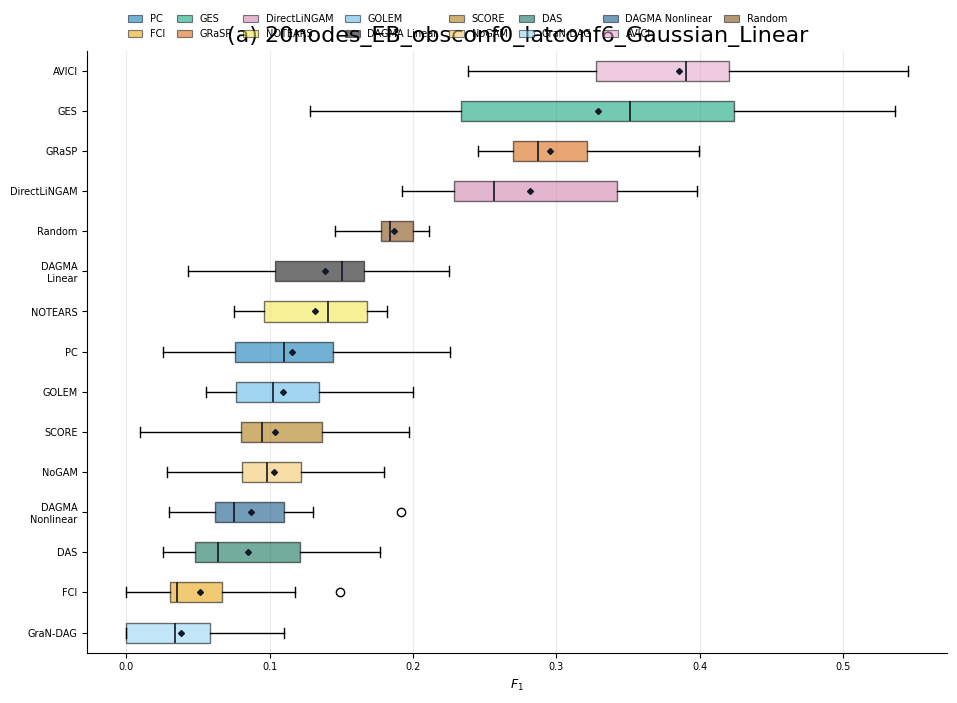

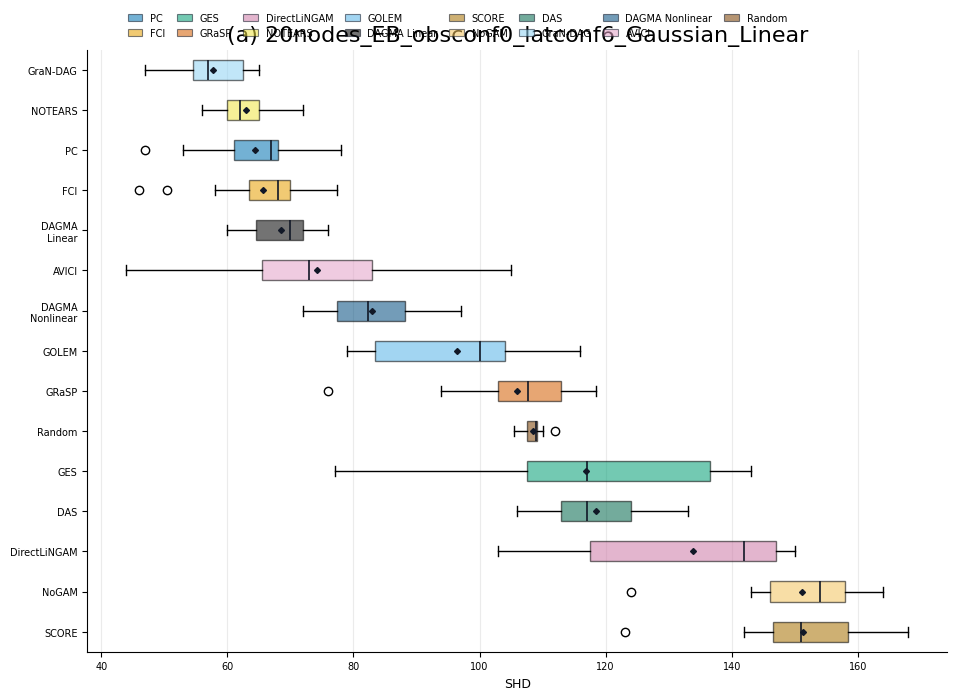

,dataset_seed,model,f1_range
0,13,AVICI,0.000000
1,13,DAGMA_Linear,0.000000
2,13,DAGMA_Nonlinear,0.138889
3,13,DAS,0.000000
4,13,DirectLiNGAM,0.000000
5,13,FCI,0.000000
6,13,GES,0.000000
7,13,GOLEM,0.000000
8,13,GRaSP,0.415534
9,13,GraNDAG,0.000000


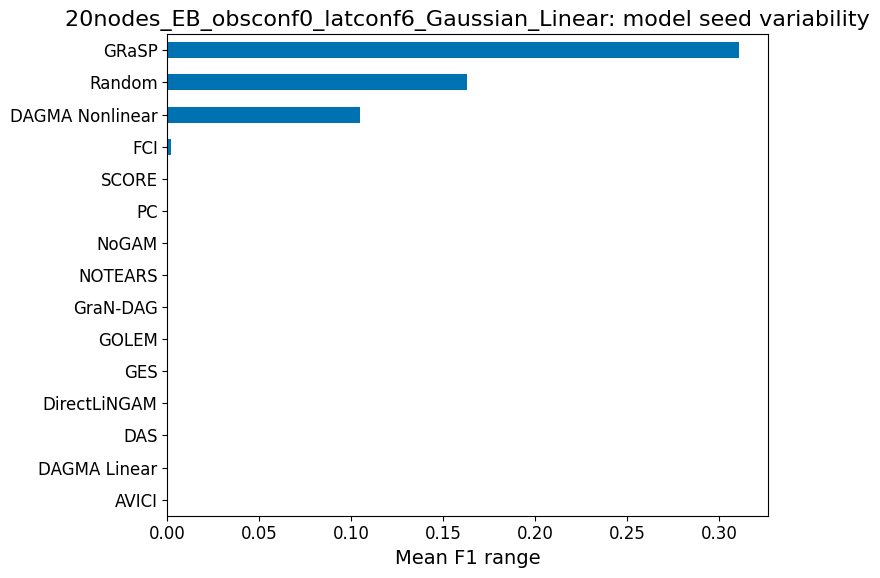

,model_seed,model,f1_range
0,0,AVICI,0.307359
1,0,DAGMA_Linear,0.181708
2,0,DAGMA_Nonlinear,0.131148
3,0,DAS,0.151899
4,0,DirectLiNGAM,0.205965
5,0,FCI,0.161290
6,0,GES,0.408234
7,0,GOLEM,0.144444
8,0,GRaSP,0.323167
9,0,GraNDAG,0.109589


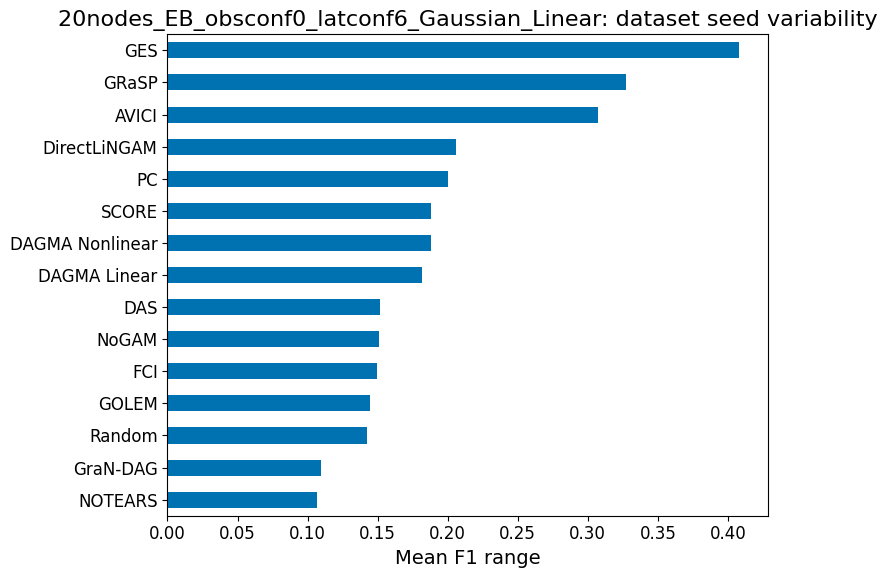

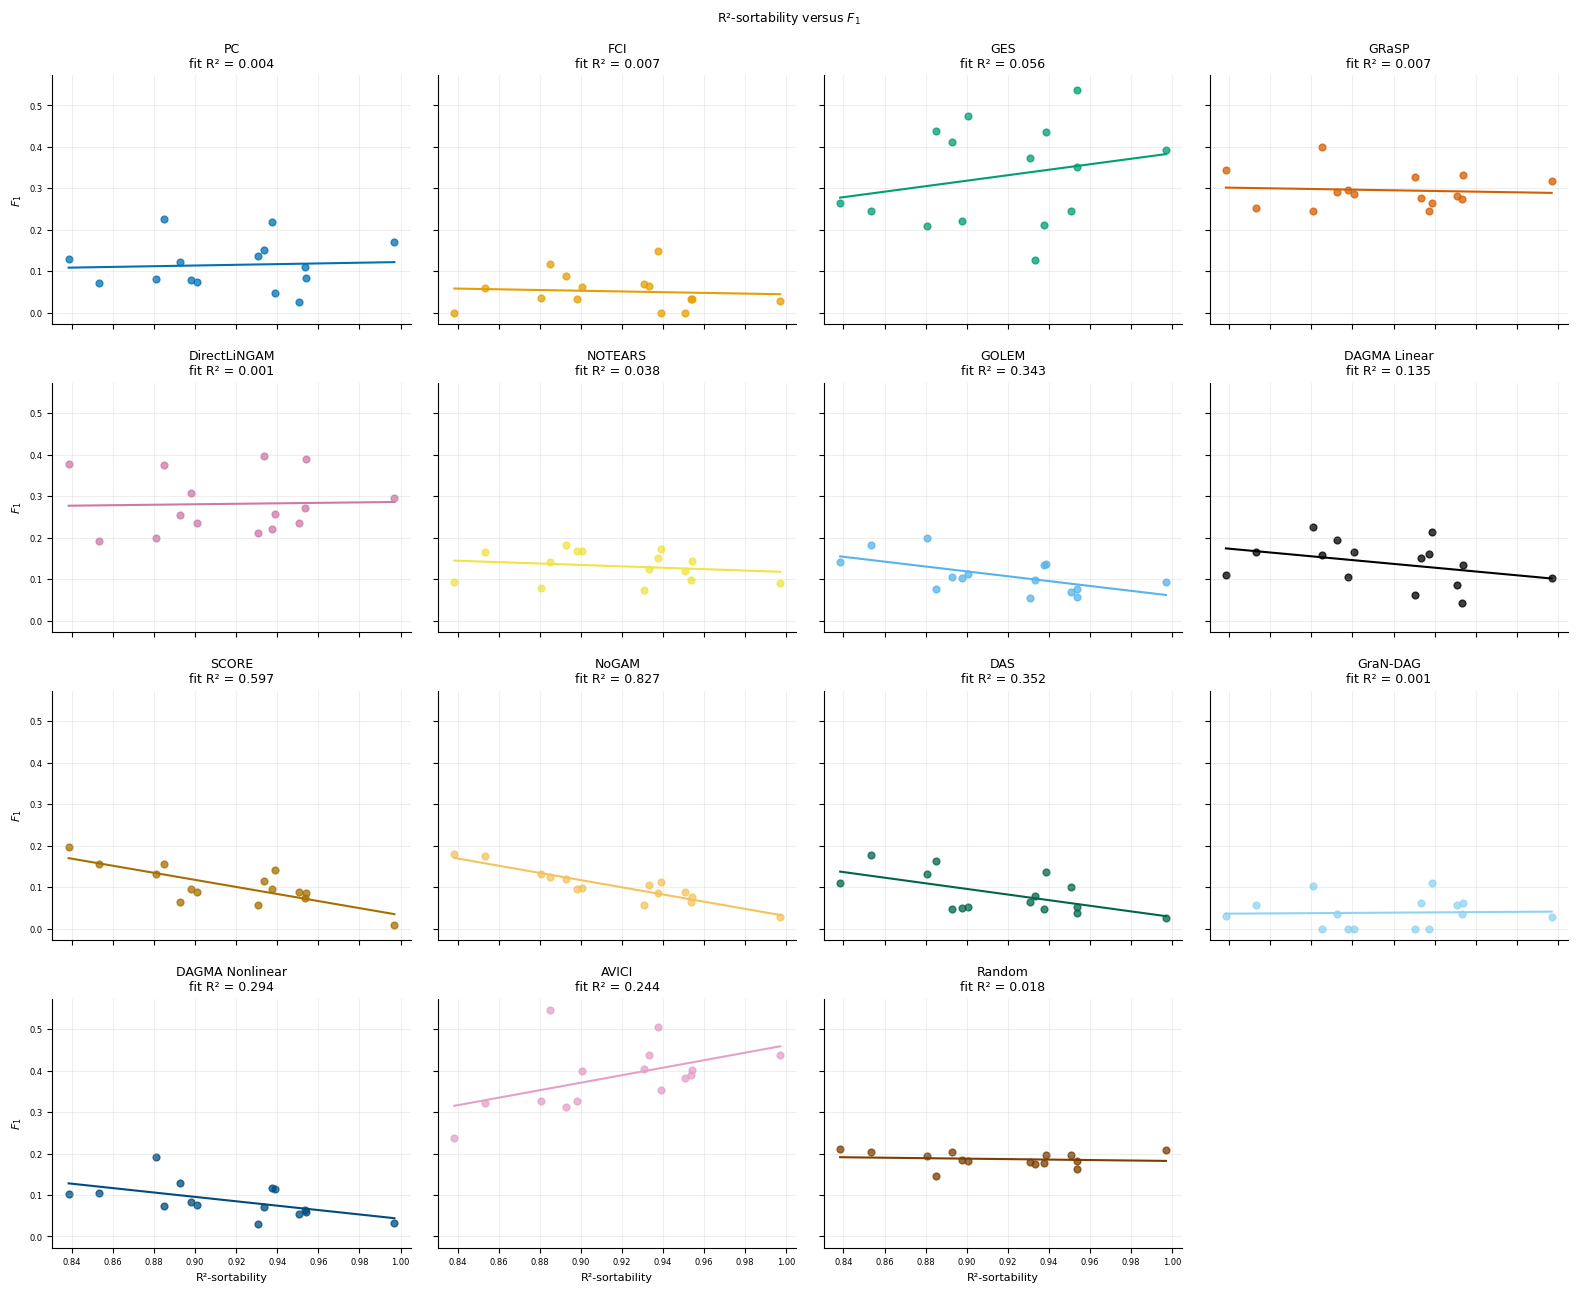

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,AVICI,0.545455,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
1,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DAGMA_Linear,0.159091,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
2,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DAGMA_Nonlinear,0.072469,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
3,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DAS,0.163522,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
4,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DirectLiNGAM,0.375691,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
5,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,FCI,0.117647,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
6,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GES,0.438710,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
7,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GOLEM,0.076923,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
8,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GRaSP,0.399152,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
9,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GraNDAG,0.000000,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.988439,0.930636,173,171,0,161,0,20,2000
1,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
2,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,1.000000,0.997024,336,336,0,335,0,20,2000
3,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.987500,0.937500,160,158,0,150,0,20,2000
4,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,1.000000,0.892617,149,149,0,133,0,20,2000
5,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.991279,0.953488,344,341,0,328,0,20,2000
6,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.919668,0.853186,361,332,0,308,0,20,2000
7,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.952020,0.838384,396,377,0,332,0,20,2000
8,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.984314,0.933333,255,251,0,238,0,20,2000
9,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.991781,0.950685,365,362,0,347,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.494389,0.244420,0.904794,-0.443433,0.061021,0.503571,0.055655
1,DAGMA_Linear,15,-0.367289,0.134901,-0.457912,0.558161,0.178064,-0.457143,0.086678
2,DAGMA_Nonlinear,15,-0.542075,0.293845,-0.529508,0.571894,0.036846,-0.585714,0.021777
3,DAS,15,-0.593098,0.351765,-0.677550,0.705355,0.019784,-0.573727,0.025334
4,DirectLiNGAM,15,0.033427,0.001117,0.056684,0.229700,0.905861,0.221429,0.427714
5,FCI,15,-0.085695,0.007344,-0.086277,0.130706,0.761385,-0.245742,0.377324
6,GES,15,0.236101,0.055744,0.661662,-0.276995,0.396906,0.228571,0.412566
7,GOLEM,15,-0.585357,0.342643,-0.586897,0.647049,0.021877,-0.614286,0.014834
8,GRaSP,15,-0.081600,0.006659,-0.080475,0.369371,0.772504,-0.021429,0.939578
9,GraNDAG,15,0.036619,0.001341,0.031332,0.009516,0.896912,0.127412,0.650905


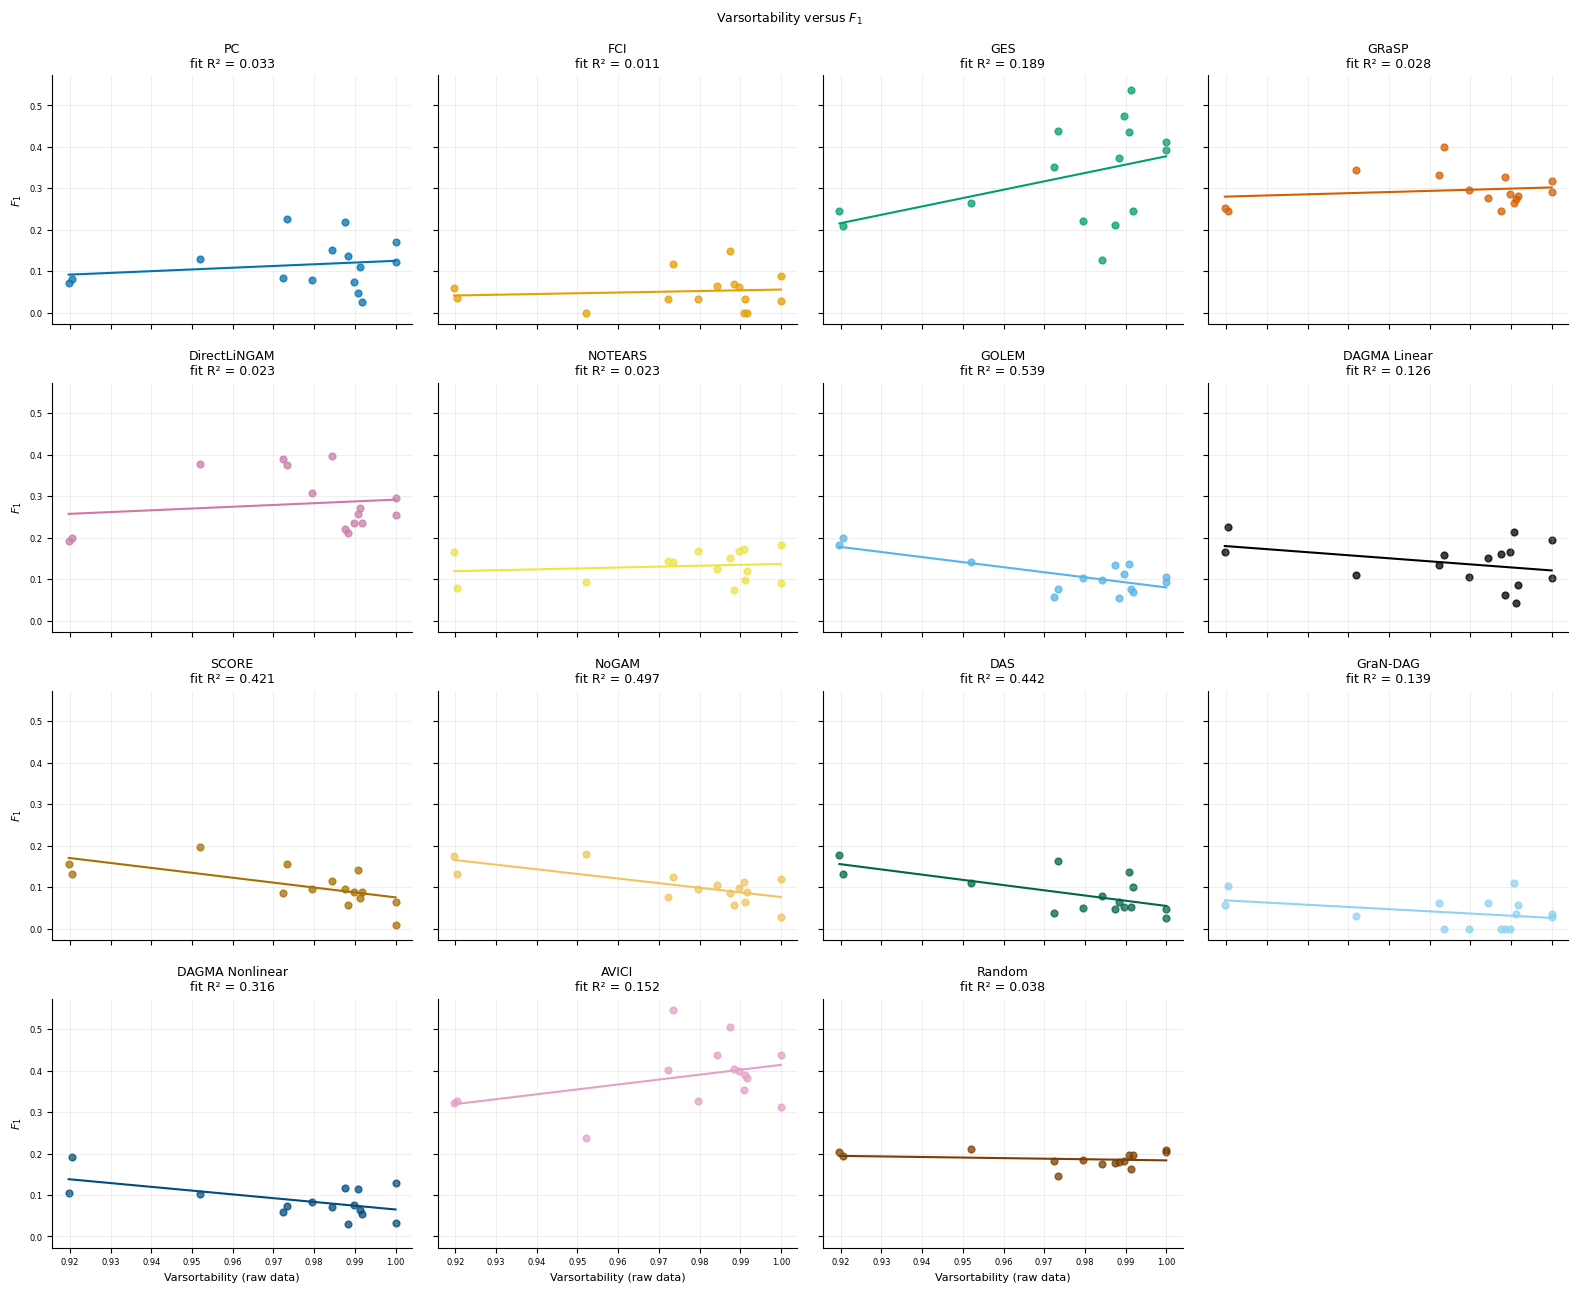

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,AVICI,0.545455,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
1,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DAGMA_Linear,0.159091,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
2,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DAGMA_Nonlinear,0.072469,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
3,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DAS,0.163522,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
4,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DirectLiNGAM,0.375691,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
5,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,FCI,0.117647,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
6,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GES,0.438710,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
7,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GOLEM,0.076923,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
8,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GRaSP,0.399152,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
9,13,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GraNDAG,0.000000,15,20,EB,0,6,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.988439,0.930636,173,171,0,161,0,20,2000
1,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.973451,0.884956,113,110,0,100,0,20,2000
2,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,1.000000,0.997024,336,336,0,335,0,20,2000
3,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.987500,0.937500,160,158,0,150,0,20,2000
4,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,1.000000,0.892617,149,149,0,133,0,20,2000
5,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.991279,0.953488,344,341,0,328,0,20,2000
6,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.919668,0.853186,361,332,0,308,0,20,2000
7,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.952020,0.838384,396,377,0,332,0,20,2000
8,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.984314,0.933333,255,251,0,238,0,20,2000
9,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.991781,0.950685,365,362,0,347,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.390443,0.152446,1.183058,-0.769182,0.150193,0.168007,0.549494
1,DAGMA_Linear,15,-0.355613,0.126461,-0.734039,0.855086,0.193320,-0.291332,0.292108
2,DAGMA_Nonlinear,15,-0.562536,0.316447,-0.909767,0.974746,0.029037,-0.307417,0.265024
3,DAS,15,-0.665190,0.442478,-1.258136,1.312601,0.006807,-0.482111,0.068771
4,DirectLiNGAM,15,0.152286,0.023191,0.427559,-0.135699,0.587949,-0.008937,0.974784
5,FCI,15,0.107035,0.011457,0.178414,-0.122495,0.704186,-0.091563,0.745531
6,GES,15,0.434602,0.188879,2.016494,-1.639027,0.105482,0.491510,0.062777
7,GOLEM,15,-0.734475,0.539454,-1.219227,1.299379,0.001818,-0.405720,0.133501
8,GRaSP,15,0.168806,0.028496,0.275628,0.026598,0.547569,0.017873,0.949590
9,GraNDAG,15,-0.373077,0.139187,-0.528501,0.554090,0.170801,-0.129348,0.645919


In [3]:
for study, frame in [("benchmark", main)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf0_latconf6_Gaussian_Linear')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,AVICI,r2_sortability,15,0.503571,0.055655,estimated,0.556545
1,benchmark,untuned,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.457143,0.086678,estimated,0.780103
2,benchmark,untuned,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.585714,0.021777,estimated,0.261318
3,benchmark,untuned,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DAS,r2_sortability,15,-0.573727,0.025334,estimated,0.278670
4,benchmark,untuned,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,DirectLiNGAM,r2_sortability,15,0.221429,0.427714,estimated,1.000000
5,benchmark,untuned,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,FCI,r2_sortability,15,-0.245742,0.377324,estimated,1.000000
6,benchmark,untuned,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GES,r2_sortability,15,0.228571,0.412566,estimated,1.000000
7,benchmark,untuned,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GOLEM,r2_sortability,15,-0.614286,0.014834,estimated,0.192841
8,benchmark,untuned,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GRaSP,r2_sortability,15,-0.021429,0.939578,estimated,1.000000
9,benchmark,untuned,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,GraNDAG,r2_sortability,15,0.127412,0.650905,estimated,1.000000
